In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Load dataset
df = pd.read_csv("Car details v3.csv")

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [2]:
# Dataset information
print("Dataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Missing values
print("\nMissing Values:")
display(df.isnull().sum())

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Unique values in categorical columns
print("\nFuel Types:")
print(df["fuel"].value_counts())

print("\nTransmission Types:")
print(df["transmission"].value_counts())

print("\nOwner Types:")
print(df["owner"].value_counts())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 825.6 KB

Statistical Summary:


,year,selling_price,km_driven,seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,5.416719
std,4.044249,8.062534e+05,5.655055e+04,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000



Missing Values:


name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           222
seats            221
dtype: int64


Duplicate Records: 1202

Fuel Types:
fuel
Diesel    4402
Petrol    3631
CNG         57
LPG         38
Name: count, dtype: int64

Transmission Types:
transmission
Manual       7078
Automatic    1050
Name: count, dtype: int64

Owner Types:
owner
First Owner             5289
Second Owner            2105
Third Owner              555
Fourth & Above Owner     174
Test Drive Car             5
Name: count, dtype: int64


In [3]:
# Create a working copy
df_clean = df.copy()

# Remove duplicate rows
print("Before removing duplicates:", df_clean.shape)

df_clean = df_clean.drop_duplicates()

print("After removing duplicates:", df_clean.shape)
print("Duplicates remaining:", df_clean.duplicated().sum())

Before removing duplicates: (8128, 13)
After removing duplicates: (6926, 13)
Duplicates remaining: 0


In [4]:
# Extract numeric values from columns
df_clean["mileage"] = pd.to_numeric(
    df_clean["mileage"].str.extract(r"(\d+\.?\d*)")[0],
    errors="coerce"
)

df_clean["engine"] = pd.to_numeric(
    df_clean["engine"].str.extract(r"(\d+\.?\d*)")[0],
    errors="coerce"
)

df_clean["max_power"] = pd.to_numeric(
    df_clean["max_power"].str.extract(r"(\d+\.?\d*)")[0],
    errors="coerce"
)

# Remove torque for now because its formats are inconsistent
df_clean = df_clean.drop(columns=["torque"])

print(df_clean.dtypes)
display(df_clean.head())

name                 str
year               int64
selling_price      int64
km_driven          int64
fuel                 str
seller_type          str
transmission         str
owner                str
mileage          float64
engine           float64
max_power        float64
seats            float64
dtype: object


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5.0


In [5]:
# Fill missing numerical values with median
numeric_cols = [
    "mileage",
    "engine",
    "max_power",
    "seats"
]

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

print("Missing values after cleaning:")
display(df_clean.isnull().sum())

print("Final dataset shape:", df_clean.shape)

Missing values after cleaning:


name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
mileage          0
engine           0
max_power        0
seats            0
dtype: int64

Final dataset shape: (6926, 12)


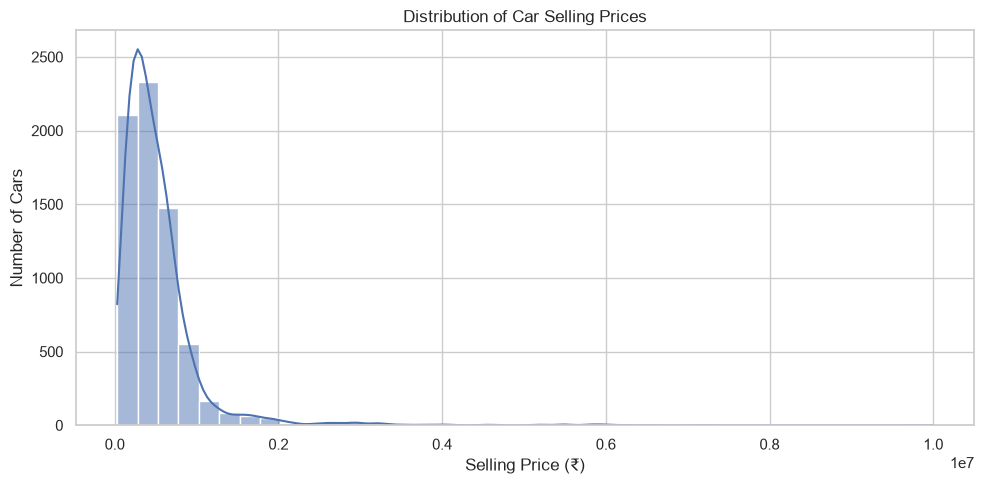

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean["selling_price"],
    bins=40,
    kde=True
)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price (₹)")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()

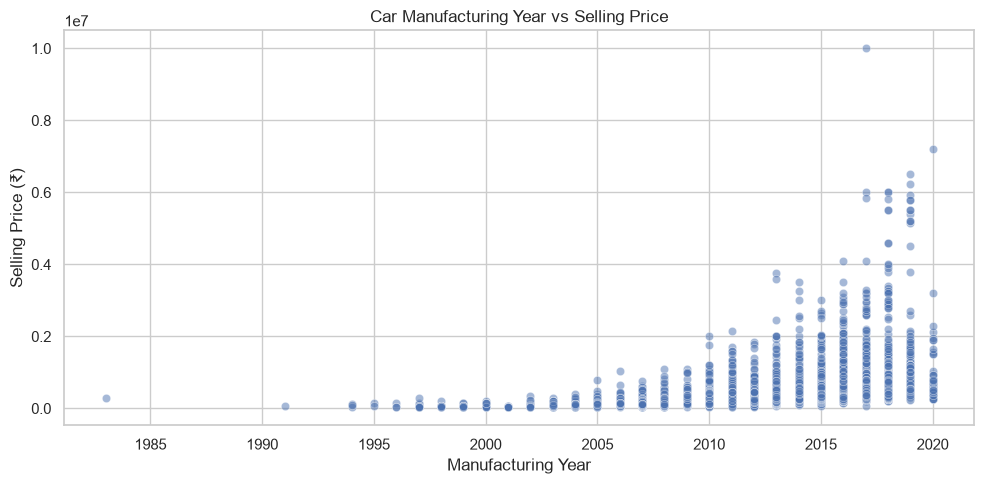

In [7]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df_clean,
    x="year",
    y="selling_price",
    alpha=0.5
)

plt.title("Car Manufacturing Year vs Selling Price")
plt.xlabel("Manufacturing Year")
plt.ylabel("Selling Price (₹)")
plt.tight_layout()
plt.show()

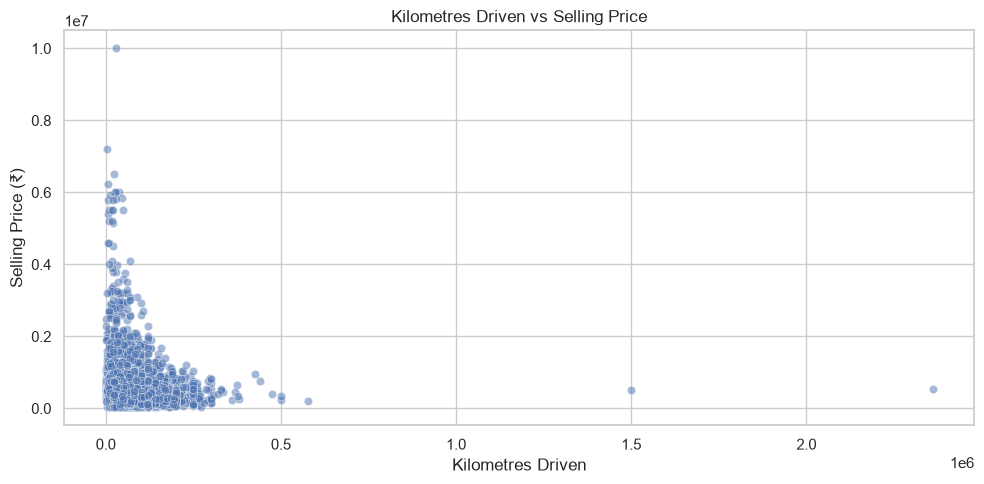

In [8]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df_clean,
    x="km_driven",
    y="selling_price",
    alpha=0.5
)

plt.title("Kilometres Driven vs Selling Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price (₹)")
plt.tight_layout()
plt.show()

In [9]:
# Check the most expensive cars
print("Top 10 expensive cars:")
display(
    df_clean.nlargest(10, "selling_price")[
        ["name", "year", "selling_price", "km_driven"]
    ]
)

# Check cars with highest kilometres driven
print("\nTop 10 cars by kilometres driven:")
display(
    df_clean.nlargest(10, "km_driven")[
        ["name", "year", "selling_price", "km_driven"]
    ]
)

# Check numerical ranges
print("\nNumerical feature ranges:")
display(
    df_clean[
        ["selling_price", "year", "km_driven",
         "mileage", "engine", "max_power"]
    ].describe()
)

Top 10 expensive cars:


,name,year,selling_price,km_driven
170,Volvo XC90 T8 Excellence BSIV,2017,10000000,30000
2938,BMW X7 xDrive 30d DPE,2020,7200000,5000
4952,Audi A6 35 TFSI Matrix,2019,6523000,23600
4950,Audi A6 35 TFSI Matrix,2019,6223000,7800
136,Mercedes-Benz S-Class S 350 CDI,2017,6000000,37000
1071,BMW 6 Series GT 630d Luxury Line,2018,6000000,28156
4766,BMW 6 Series GT 630d Luxury Line,2018,6000000,27000
4951,Audi A6 35 TFSI Matrix,2019,5923000,11500
148,Mercedes-Benz S-Class S 350 CDI,2017,5850000,47000
6258,BMW 6 Series GT 630d Luxury Line,2018,5830000,30000



Top 10 cars by kilometres driven:


,name,year,selling_price,km_driven
3486,Hyundai i20 Asta 1.2,2007,550000,2360457
1810,Mahindra XUV500 W6 2WD,2012,500000,1500000
3508,Maruti Wagon R LXI Minor,2010,194000,577414
3641,Maruti Wagon R VXI BS IV,2011,229999,500000
6673,Toyota Innova 2.5 EV Diesel PS 7 Seater BSIII,2011,350000,500000
5106,Mahindra Scorpio M2DI,2011,400000,475000
5189,Toyota Innova 2.5 VX (Diesel) 7 Seater,2013,750000,440000
5467,Toyota Innova 2.5 VX (Diesel) 7 Seater BS IV,2010,950000,426000
2272,Mahindra Bolero SLE,2010,260000,380000
7102,Toyota Innova 2.5 V Diesel 8-seater,2007,350000,376412



Numerical feature ranges:


,selling_price,year,km_driven,mileage,engine,max_power
count,6.926000e+03,6926.000000,6.926000e+03,6926.000000,6926.000000,6926.000000
mean,5.172707e+05,2013.420300,7.399568e+04,19.464550,1425.398787,87.551527
std,5.197670e+05,4.078286,5.835810e+04,3.987878,487.026967,31.311523
min,2.999900e+04,1983.000000,1.000000e+00,0.000000,624.000000,0.000000
25%,2.500000e+05,2011.000000,4.000000e+04,16.950000,1197.000000,68.000000
50%,4.000000e+05,2014.000000,7.000000e+04,19.440000,1248.000000,81.830000
75%,6.335000e+05,2017.000000,1.000000e+05,22.320000,1498.000000,99.000000
max,1.000000e+07,2020.000000,2.360457e+06,42.000000,3604.000000,400.000000


In [10]:
# Check zero or invalid specifications
print("Zero mileage records:")
display(df_clean[df_clean["mileage"] == 0])

print("\nZero max power records:")
display(df_clean[df_clean["max_power"] == 0])

print("\nCars driven above 5 lakh km:")
display(
    df_clean[df_clean["km_driven"] > 500000][
        ["name", "year", "selling_price", "km_driven"]
    ]
)

print("\nCars with very high selling prices:")
display(
    df_clean[df_clean["selling_price"] > 5000000][
        ["name", "year", "selling_price"]
    ]
)

Zero mileage records:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats
644,Tata Indica Vista Aura Safire Anniversary Edition,2009,135000,28900,Petrol,Individual,Manual,Second Owner,0.0,1172.0,65.00,5.0
785,Hyundai Santro Xing GL,2009,120000,90000,Petrol,Individual,Manual,Second Owner,0.0,1086.0,62.00,5.0
1649,Hyundai Santro Xing GL,2008,105000,128000,Petrol,Individual,Manual,First Owner,0.0,1086.0,62.00,5.0
1676,Mercedes-Benz M-Class ML 350 4Matic,2011,1700000,110000,Diesel,Individual,Automatic,Third Owner,0.0,2987.0,165.00,5.0
2137,Land Rover Freelander 2 TD4 HSE,2013,1650000,64788,Diesel,Dealer,Automatic,First Owner,0.0,2179.0,115.00,5.0
2366,Hyundai Santro Xing (Non-AC),2010,110000,80000,Petrol,Individual,Manual,Second Owner,0.0,1086.0,62.10,5.0
2725,Hyundai Santro Xing (Non-AC),2013,184000,15000,Petrol,Individual,Manual,First Owner,0.0,1086.0,62.10,5.0
5276,Hyundai Santro Xing GL,2008,175000,40000,Petrol,Individual,Manual,First Owner,0.0,1086.0,62.00,5.0
5843,Volkswagen Polo GT TSI BSIV,2014,574000,28080,Petrol,Dealer,Automatic,First Owner,0.0,1197.0,103.25,5.0
5846,Volkswagen Polo GT TSI BSIV,2014,575000,28100,Petrol,Dealer,Automatic,First Owner,0.0,1197.0,103.25,5.0



Zero max power records:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats
575,Maruti Alto K10 LXI,2011,204999,97500,Petrol,Individual,Manual,First Owner,19.44,1248.0,0.0,5.0
1442,Maruti Swift Dzire VDI Optional,2017,589000,41232,Diesel,Dealer,Manual,First Owner,19.44,1248.0,0.0,5.0
2549,Tata Indica Vista Quadrajet LS,2012,240000,70000,Diesel,Individual,Manual,First Owner,19.44,1248.0,0.0,5.0



Cars driven above 5 lakh km:


,name,year,selling_price,km_driven
1810,Mahindra XUV500 W6 2WD,2012,500000,1500000
3486,Hyundai i20 Asta 1.2,2007,550000,2360457
3508,Maruti Wagon R LXI Minor,2010,194000,577414



Cars with very high selling prices:


,name,year,selling_price
132,Lexus ES 300h,2019,5150000
136,Mercedes-Benz S-Class S 350 CDI,2017,6000000
139,BMW X4 M Sport X xDrive20d,2019,5800000
148,Mercedes-Benz S-Class S 350 CDI,2017,5850000
170,Volvo XC90 T8 Excellence BSIV,2017,10000000
384,BMW X4 M Sport X xDrive20d,2019,5400000
385,BMW X4 M Sport X xDrive20d,2019,5500000
1071,BMW 6 Series GT 630d Luxury Line,2018,6000000
2938,BMW X7 xDrive 30d DPE,2020,7200000
4671,BMW 5 Series 520d Luxury Line,2019,5200000


In [11]:
# Create a separate dataset for modelling
df_model = df_clean.copy()

# Replace invalid zero specifications with NaN
df_model["mileage"] = df_model["mileage"].replace(0, np.nan)
df_model["max_power"] = df_model["max_power"].replace(0, np.nan)

# Remove extremely suspicious kilometre readings
df_model = df_model[df_model["km_driven"] <= 500000].copy()

# Fill missing numerical values using median
numeric_cols = [
    "mileage",
    "engine",
    "max_power",
    "seats"
]

for col in numeric_cols:
    df_model[col] = df_model[col].fillna(df_model[col].median())

print("Dataset before final preparation:", df_clean.shape)
print("Dataset after final preparation:", df_model.shape)

print("\nRemaining missing values:")
display(df_model.isnull().sum())

print("\nFinal dataset preview:")
display(df_model.head())

Dataset before final preparation: (6926, 12)
Dataset after final preparation: (6923, 12)

Remaining missing values:


name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
mileage          0
engine           0
max_power        0
seats            0
dtype: int64


Final dataset preview:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5.0


In [12]:
from sklearn.model_selection import train_test_split

# Select input features
X = df_model.drop(columns=["selling_price", "name"])

# Select target
y = df_model["selling_price"]

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5538, 10)
Testing features: (1385, 10)
Training target: (5538,)
Testing target: (1385,)


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
numeric_features = [
    "year",
    "km_driven",
    "mileage",
    "engine",
    "max_power",
    "seats"
]

categorical_features = [
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Preprocessing setup completed!")

Numerical features: ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']
Categorical features: ['fuel', 'seller_type', 'transmission', 'owner']
Preprocessing setup completed!


In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Define models
models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

results = []

# Train and evaluate each model
for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Train
    pipeline.fit(X_train, y_train)

    # Predict
    predictions = pipeline.predict(X_test)

    # Evaluate
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    print(f"\n{name}")
    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 4))

# Display comparison
results_df = pd.DataFrame(results)
display(results_df)


Linear Regression
MAE: 181399.77
RMSE: 339603.86
R2 Score: 0.6232

Random Forest
MAE: 80483.19
RMSE: 164274.67
R2 Score: 0.9118


,Model,MAE,RMSE,R2 Score
0,Linear Regression,181399.770845,339603.858705,0.623220
1,Random Forest,80483.185311,164274.673181,0.911837


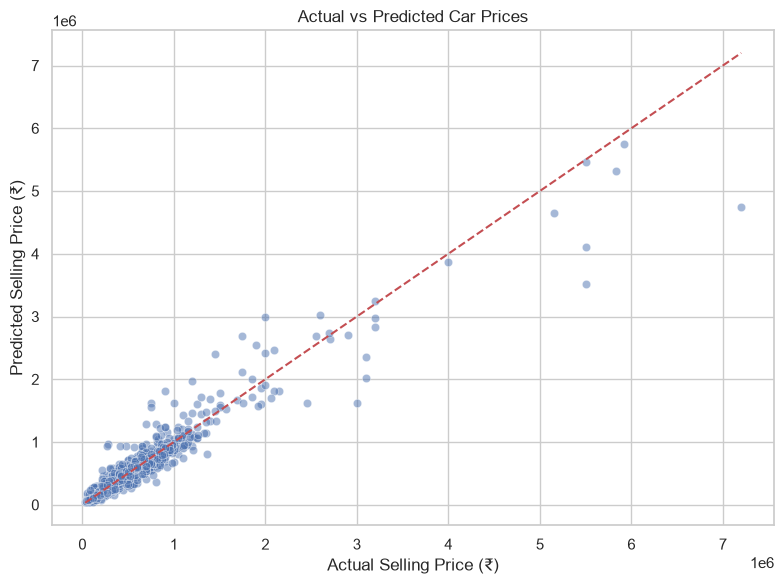

In [15]:
# Train the best model separately
best_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

best_model.fit(X_train, y_train)

# Predictions
y_pred = best_model.predict(X_test)

# Actual vs predicted plot
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.title("Actual vs Predicted Car Prices")
plt.xlabel("Actual Selling Price (₹)")
plt.ylabel("Predicted Selling Price (₹)")
plt.tight_layout()
plt.show()

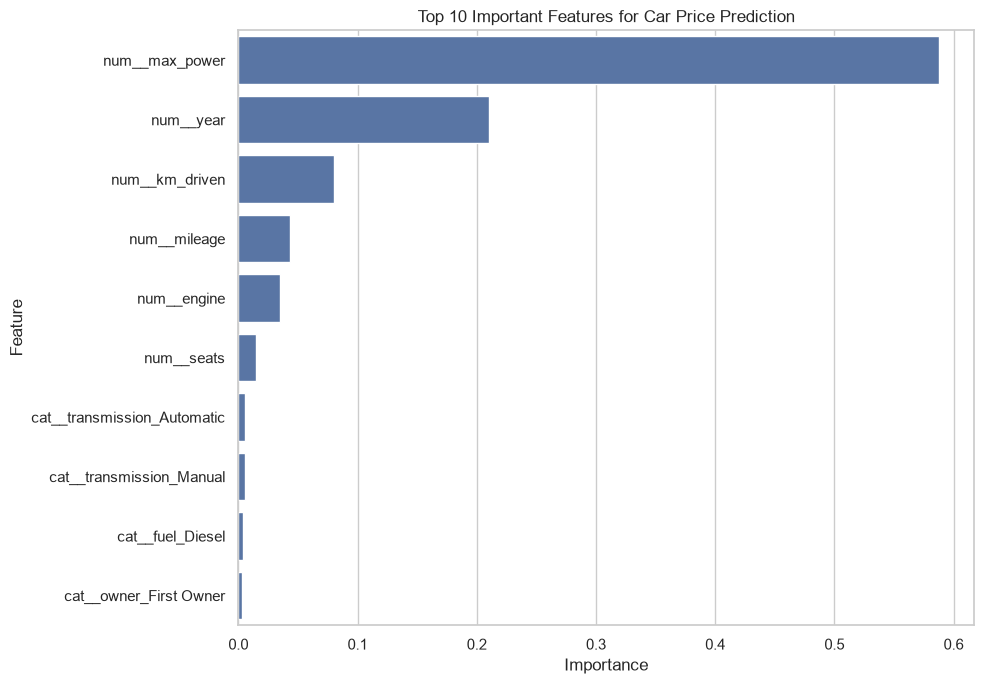

,Feature,Importance
4,num__max_power,0.587722
0,num__year,0.210485
1,num__km_driven,0.080218
2,num__mileage,0.042890
3,num__engine,0.034876
5,num__seats,0.014738
13,cat__transmission_Automatic,0.005625
14,cat__transmission_Manual,0.005510
7,cat__fuel_Diesel,0.003499
15,cat__owner_First Owner,0.002956


In [16]:
# Get feature importance from Random Forest
feature_names = best_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importances = best_model.named_steps[
    "model"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features for Car Price Prediction")
plt.tight_layout()
plt.show()

display(importance_df.head(10))

In [17]:
sample_car = pd.DataFrame([{
    "year": 2018,
    "km_driven": 45000,
    "fuel": "Petrol",
    "seller_type": "Individual",
    "transmission": "Manual",
    "owner": "First Owner",
    "mileage": 20.0,
    "engine": 1197,
    "max_power": 82.0,
    "seats": 5
}])

predicted_price = best_model.predict(sample_car)

print(f"Predicted Car Price: ₹{predicted_price[0]:,.2f}")

Predicted Car Price: ₹472,449.90


In [18]:
import os
import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(best_model, "models/car_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!
